# Credit Card Fraud Detection — Case Study



## The data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
df = pd.read_csv("/content/drive/MyDrive/Credit_Card_Fraud_Detection/creditcard.csv")

df.shape

(284807, 31)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df["Class"].value_counts()

,count
Class,
0,284315
1,492


`Class` is 1 for fraud, 0 for legitimate. `Amount` is the transaction dollar amount and `Time` is seconds since the first transaction in the dataset. Every other column (`V1`...`V28`) has been anonymized by the bank for privacy — they're real signal, just not human-readable.

0.1727% of transactions are fraud (492 out of 284807)


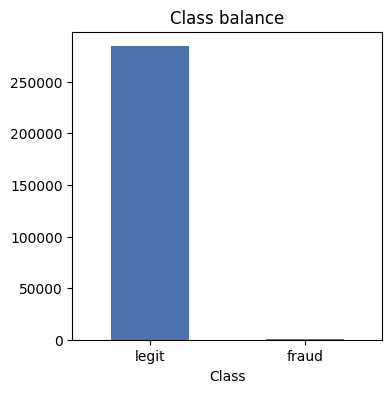

In [ ]:
fraud_rate = df["Class"].mean()
print(f"{fraud_rate:.4%} of transactions are fraud ({df['Class'].sum()} out of {len(df)})")

plt.figure(figsize=(4, 4))
df["Class"].value_counts().plot(kind="bar", color=["#4C72B0", "#C44E52"])
plt.xticks([0, 1], ["legit", "fraud"], rotation=0)
plt.title("Class balance")
plt.show()

In [ ]:
df.groupby("Class")["Amount"].describe()[["count", "mean", "50%", "max"]]

,count,mean,50%,max
Class,,,,
0,284315.0,88.291022,22.00,25691.16
1,492.0,122.211321,9.25,2125.87


In [ ]:
x=df.drop("Class",axis=1)
x = x.astype('float32')
y=df["Class"]

# Data Modelling

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
fraud_classifier=RandomForestClassifier(max_depth=5)
fraud_classifier.fit(x_train,y_train)


array([1, 0, 0, ..., 0, 0, 0])

In [ ]:
train_predictions=fraud_classifier.predict(x_train)
train_predictions

In [ ]:
test_predictions=fraud_classifier.predict(x_test)
predictions

# Classification Report

In [ ]:
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.92      0.70      0.80        98

    accuracy                           1.00     56962
   macro avg       0.96      0.85      0.90     56962
weighted avg       1.00      1.00      1.00     56962



# Conclusion:
1. The model was able to find 70% of the fradulent cases and it was 92% correct.
2. The legitimate cases and fraud cases ratio was one sided, regardless the    model still learned patterns
